# 06 - Ordering the work units, evaluating the plan, writing the submission file

**Author of this notebook:** Qusai (qusai branch). Plan step 5, part 2 of 2.
Input: `data/processed/circles_unordered_v1.csv` from notebook 05.

## Why does order matter?
* Money arrives at $10M a year and units are dug **strictly in file order**, so a
  circle's position decides **which year** it is dug.
* A pipe still in the ground in year *y* has had *y* years to leak:
  expected loss = `leak_cost x (1 - (1 - p)^y)`.
* Every pipe is replaced exactly once whatever the order, so total replacement spend is
  (almost) fixed - **the order only changes the leak bill.**

## The ordering rule (Smith's rule, iterated)
For a single worker doing jobs one after another, the order that minimises
`sum(weight x finish time)` is *largest weight / duration first*. Here
* duration = what the circle costs (money is the scarce resource, so cost plays the role of time),
* weight = expected dollars lost **per year** if the circle's pipes stay in the ground
  (`sum of K x hazard` over the pipes it replaces).

So: dig first the circles that remove the most expected leak-loss per dollar spent.
The weight shrinks with time (pipes that survive are, by definition, still intact, and
the survival probability decays), so we iterate: schedule -> estimate each circle's
year -> recompute weights at that year -> re-sort (8 rounds, damped).

In [1]:
from pathlib import Path
import sys

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pipeplan.world import load_world
from pipeplan.simulator import prepare, expected_score, monte_carlo
from pipeplan.ordering import smith_order, baseline_orders, permute, drop_redundant
from pipeplan.pipeline import (circle_table, write_submission, read_submission,
                               independent_coverage_check)

pd.set_option("display.width", 160)
w = load_world()
circles = pd.read_csv(ROOT / "data/processed/circles_unordered_v1.csv").to_numpy()
prep0 = prepare(w, circles)
print(len(circles), "circles | covers all iron:", prep0.covers_all_iron)

12981 circles | covers all iron: True


## 1. Does the ordering rule beat simpler orderings?
Same circles, six orderings. Scored two ways: the fast `expected_score`, and the
Monte Carlo average over 25 random futures (event-exact rules, notebook 04).
* *random* - no thought at all
* *by x coordinate* - sweep west to east (what a "work through the map" plan would do)
* *by max leak probability* - riskiest single pipe first
* *by total loss rate* - biggest expected annual loss first, ignoring cost
* *static Smith* - loss rate per dollar at time 0 (one pass of the rule)
* *iterated Smith* - the final rule (below)

In [2]:
best, log = smith_order(w, prep0, iters=8, verbose=True)

iter 0: score $72,828,861  spend $140,534,434  leak $36,636,705  last year 14


iter 1: score $73,172,306  spend $140,534,434  leak $36,293,260  last year 14


iter 2: score $73,189,319  spend $140,534,434  leak $36,276,247  last year 14


iter 3: score $73,204,283  spend $140,534,434  leak $36,261,282  last year 14


iter 4: score $73,211,055  spend $140,534,434  leak $36,254,511  last year 14


iter 5: score $73,212,303  spend $140,534,434  leak $36,253,262  last year 14


iter 6: score $73,215,989  spend $140,534,434  leak $36,249,577  last year 14


iter 7: score $73,217,089  spend $140,534,434  leak $36,248,477  last year 14


iter 8: score $73,214,512  spend $140,534,434  leak $36,251,054  last year 14


In [3]:
rows = []
orders = baseline_orders(w, prep0)
variants = {k: permute(prep0, o) for k, o in orders.items()}
variants["iterated Smith (final)"] = best
for name, p in variants.items():
    e = expected_score(w, p)
    m = monte_carlo(w, p, n_draws=25, seed=11)
    rows.append({"ordering": name,
                 "expected_score_M": e["score"] / 1e6, "expected_leak_M": e["leak_cost"] / 1e6,
                 "MC_score_M": m["score_mean"] / 1e6, "MC_score_sd_M": m["score_sd"] / 1e6})
cmp = pd.DataFrame(rows).round(2)
cmp

,ordering,expected_score_M,expected_leak_M,MC_score_M,MC_score_sd_M
0,random,-16.07,125.48,17.69,3.17
1,by_x_coordinate,0.68,108.73,31.46,2.84
2,by_max_leak_probability,22.34,87.13,45.58,2.50
3,by_total_loss_rate,55.05,54.43,80.61,1.42
4,by_loss_per_dollar (static Smith),72.77,36.62,94.61,1.13
5,iterated Smith (final),73.22,36.25,95.74,1.04


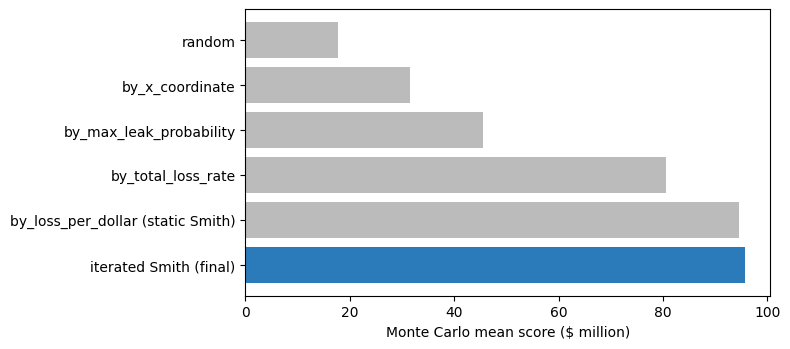

In [4]:
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.barh(cmp["ordering"], cmp["MC_score_M"], color=["#bbb"] * (len(cmp) - 1) + ["#2b7bba"])
ax.set_xlabel("Monte Carlo mean score ($ million)")
ax.invert_yaxis()
plt.tight_layout(); plt.show()

The ordering is worth tens of millions of dollars: a random order scores about $18M in
Monte Carlo, against about $96M for the Smith order. Both scoring methods rank the six
orderings the same way, so optimising the fast score is safe. (We have not proven the
Smith order optimal - only that it beats these alternatives.)

### Convergence of the iteration
Iteration 0 is plain Smith (weights at time 0); later iterations re-weight each circle at
the year it is scheduled for. It gains ~$0.4M and flattens out.

In [5]:
pd.DataFrame(log).assign(score_M=lambda d: d.score / 1e6, leak_M=lambda d: d.leak / 1e6)[["iter", "score_M", "leak_M", "last_year"]].round(3)

,iter,score_M,leak_M,last_year
0,0,72.829,36.637,14
1,1,73.172,36.293,14
2,2,73.189,36.276,14
3,3,73.204,36.261,14
4,4,73.211,36.255,14
5,5,73.212,36.253,14
6,6,73.216,36.250,14
7,7,73.217,36.248,14
8,8,73.215,36.251,14


## 2. The final plan

In [6]:
# Remove circles that would be skipped (all their pipes are replaced earlier). One safety
# guard: a skipped circle is kept if it is the only one containing some iron pipe with at
# least 4 cm to spare (otherwise that pipe would hang on a circle that holds it by a few mm).
final = drop_redundant(w, best)
print("circles:", prep0.n, "->", final.n, "after dropping circles whose pipes are all replaced earlier")
table = circle_table(w, final)

by_year = table.groupby("year").agg(
    circles=("order", "size"), pipes=("pipes_replaced", "sum"), iron=("iron_replaced", "sum"),
    metres=("metres_replaced", "sum"), spend=("exec_cost", "sum"), loss_rate_removed=("loss_rate_replaced", "sum"),
)
by_year["share_of_initial_loss_rate_%"] = 100 * by_year.loss_rate_removed / by_year.loss_rate_removed.sum()
by_year["cum_share_%"] = by_year["share_of_initial_loss_rate_%"].cumsum()
by_year.round(1)

circles: 12981 -> 12824 after dropping circles whose pipes are all replaced earlier


,circles,pipes,iron,metres,spend,loss_rate_removed,share_of_initial_loss_rate_%,cum_share_%
year,,,,,,,,
2027.0,1216,2072,1857,32416.2,9994999.2,15876742.9,58.6,58.6
2028.0,1228,2257,2163,31241.9,10004706.4,3679802.1,13.6,72.2
2029.0,1161,2361,2328,30803.0,9990999.0,2055350.0,7.6,79.8
2030.0,835,1869,1846,29293.8,9965717.1,1433973.4,5.3,85.1
2031.0,784,1626,1615,27991.2,10035896.7,1106150.2,4.1,89.2
2032.0,882,1776,1766,29098.7,10007136.4,820566.0,3.0,92.2
2033.0,718,2307,2301,32643.5,9993791.8,559113.3,2.1,94.3
2034.0,1193,2972,2968,37674.3,10005830.2,370004.5,1.4,95.6
2035.0,1149,2840,2840,39928.7,9984954.3,282175.4,1.0,96.7


(A "guard" circle - kept only for the coverage-margin safety rule - has year `NaN`: the real rules skip it for free.)

`loss_rate_removed` is the expected $/year of leaks that disappears when the year's
circles are dug. Front-loading is clear: the first years remove a large share of the
total expected loss with a small share of the money.

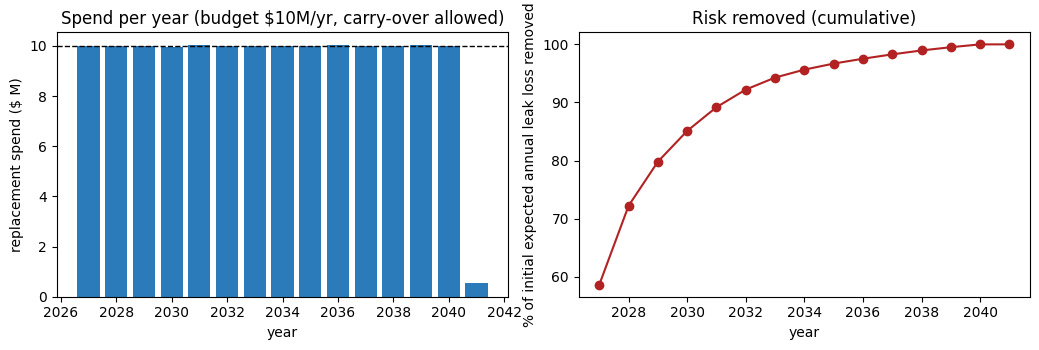

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(10.5, 3.6))
ax[0].bar(by_year.index, by_year.spend / 1e6, color="#2b7bba")
ax[0].axhline(10, color="k", ls="--", lw=1)
ax[0].set_ylabel("replacement spend ($ M)"); ax[0].set_title("Spend per year (budget $10M/yr, carry-over allowed)")
ax[1].plot(by_year.index, by_year["cum_share_%"], "o-", color="firebrick")
ax[1].set_ylabel("% of initial expected annual leak loss removed"); ax[1].set_title("Risk removed (cumulative)")
for a in ax:
    a.set_xlabel("year")
plt.tight_layout(); plt.show()

## 3. Write the submission file and verify it from the file itself
Format (professor): one line per work unit, `"(x, y)",r`. After writing we **re-read the
file** with a strict parser and run the independent brute-force coverage check on what
came back, so what we verify is exactly what would be uploaded.

In [8]:
sub = ROOT / "submission" / "submission_v1.csv"
write_submission(final.circles, sub)
print(sub.read_text().splitlines()[:3])

back = read_submission(sub)                       # raises if any line is malformed
cov = independent_coverage_check(w, back)
prep_back = prepare(w, back)
print(f"\nlines: {len(back)}")
print(f"iron pipes: {cov['n_required']}, uncovered: {cov['n_uncovered']}, tightest margin {cov['min_margin_m']:.3f} m")
assert cov["n_uncovered"] == 0

['"(1172.80, 4604.82)",1.69', '"(3759.84, 1603.46)",3.57', '"(1011.79, 4204.32)",2.29']



lines: 12824
iron pipes: 26245, uncovered: 0, tightest margin 0.048 m


## 4. Predicted score
* `expected_score`: fast, conservative (leaks never make a later circle cheaper).
* `monte_carlo`: event-exact rules over 100 random futures (mean leak cost per leak).

In [9]:
ex = expected_score(w, prep_back)
mc = monte_carlo(w, prep_back, n_draws=100, seed=2)
res = pd.DataFrame({
    "expected_score (conservative)": [ex["spend"], ex["surplus"], ex["leak_cost"], ex["score"], 2027 + ex["last_year"]],
    "Monte Carlo mean": [mc["spend_mean"], 250e6 - mc["spend_mean"], mc["leak_cost_mean"], mc["score_mean"], 2027 + mc["last_year_mean"]],
    "Monte Carlo sd": [mc["spend_sd"], mc["spend_sd"], mc["leak_cost_sd"], mc["score_sd"], mc["last_year_sd"]],
}, index=["replacement spend $", "surplus $", "leak cost $", "score $", "last work year"])
res.round(1)

,expected_score (conservative),Monte Carlo mean,Monte Carlo sd
replacement spend $,140534434.1,120295061.5,407075.1
surplus $,109465565.9,129704938.5,407075.1
leak cost $,36248476.7,34053459.6,958093.8
score $,73217089.2,95651478.9,869206.0
last work year,2041.0,2038.8,0.4


## 5. How to use / what to check on the website
1. Upload `submission/submission_v1.csv`. **First check it is accepted** (not rejected).
   Acceptance tests our coverage logic and the 25-year feasibility.
2. Compare the website score with our range. Expect the real score to differ: the real
   future leaks are one random draw with heavy-tailed costs, and our leak model is only an
   estimate. A score *far* outside `Monte Carlo mean +/- 3 sd` (and especially outside
   the conservative `expected_score`) suggests a rule we mis-read - tell me / the group and
   we will adjust the simulator.
3. The cost of the leaks that really happen is mostly **road** pipes and a few huge
   leaks; one unlucky draw can move the score by millions.

## Known limitations
* The order inside the plan is a heuristic (iterated Smith); we did not prove it optimal.
  Packing circles tightly against the year boundaries could add a little.
* Circles are built without knowing the ordering (the delay penalty uses a provisional
  schedule). A joint optimisation could do better.
* All numbers rest on Cheryl's leak-risk model and its constant-hazard assumption.
* Nothing here has been checked against the real evaluator yet.